# Parte VI. Aprendizaje de representación en grafos

**Integrantes:** Ricardo Acuña, Juan Aquino y Camilo Soto.

**Pregunta que responde.** ¿Se puede resumir la posición de cada proveedor en la red de competencia en un vector, y ese vector sirve para algo? Un embedding de nodo es una coordenada: proveedores con coordenadas cercanas ocupan lugares parecidos de la red. Se usa en dos tareas concretas. La primera es **anticipar con quién va a competir un proveedor**, que es predicción de enlaces. La segunda es **comparar lentes**: si los grupos que salen de los embeddings coinciden con los perfiles de comportamiento de la Parte II, con las comunidades de la Parte V, con la región o con el rubro. Esta segunda tarea responde la pregunta de convergencia de la Parte VII.

**Dos grafos sobre los mismos proveedores.** Los 12 mil proveedores recurrentes, los que tienen perfil en la Parte II:

1. **Coparticipación**: el grafo de la Parte I restringido a ellos. Dice con quién compite cada uno.
2. **KNN de rasgos**: cada proveedor unido a sus 10 vecinos más parecidos en los 12 rasgos de la Parte II. Dice a quién se parece en comportamiento. Es el grafo KNN que menciona el enunciado y aquí sirve de contraste.

**Dónde corre.** En local. SVD, caminatas y skip-gram están escritos en numpy y scipy, sin bibliotecas de grafos; el grafo tiene unos 10 mil nodos y 400 mil aristas, y cabe en memoria. Los embeddings se guardan en disco para no reentrenarlos.

In [1]:
import sys, time, pickle
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "notebooks" / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score

from helpers import (BASE, FIGS, ARTEFACTOS, FIGURAS, HALLAZGOS, PALETA,
                     AZUL, ROJO, VERDE, MORADO, TEAL, TINTA, SUAVE, REJILLA, fmt, MILES,
                     cronometro, figura, exportar, hallazgo, barras_h, mapa_calor)
from representacion import (grafo_knn, embedding_svd, caminatas_node2vec, skipgram,
                            reservar_aristas, auc_enlaces, verificar)
from comunidades import ari, nmi
from gnn import entrenar as entrenar_gnn, auc_producto, verificar as verificar_gnn

pd.set_option("display.width", 190)
pd.set_option("display.max_colwidth", 64)

RECALCULAR = False
CACHE = BASE / "parte6"
CACHE.mkdir(exist_ok=True)
def guardado(nombre, calcular):
    ruta = CACHE / f"{nombre}.pkl"
    if RECALCULAR or not ruta.exists():
        with open(ruta, "wb") as f:
            pickle.dump(calcular(), f)
    with open(ruta, "rb") as f:
        return pickle.load(f)

print("pruebas de caminatas y skip-gram sobre dos cliques:", verificar())
print("pruebas de GCN, GraphSAGE y GAT sobre dos cliques:", verificar_gnn())
ar = pd.read_parquet(BASE / "grafo_aristas")
clusters = pd.read_parquet(BASE / "clusters_proveedores")
perfiles = pd.read_csv(ARTEFACTOS / "p2_perfiles.csv")[["cluster", "perfil"]]
nod = pd.read_parquet(BASE / "grafo_nodos")[["nodo", "nombre", "tipo", "monto_total"]]
com = pd.read_parquet(BASE / "parte5" / "comunidades_nacionales.parquet")
item_tipico = pd.read_parquet(BASE / "parte4" / "nombre_familia.parquet").item_tipico
rasgos = pd.read_parquet(BASE / "caracteristicas_proveedores")

pruebas de caminatas y skip-gram sobre dos cliques: True


pruebas de GCN, GraphSAGE y GAT sobre dos cliques: True


## 1. El grafo de competencia de los proveedores recurrentes

Se toma el grafo de coparticipación entre los proveedores recurrentes y su componente gigante. Cada nodo lleva cuatro etiquetas para comparar después: su perfil de la Parte II, su comunidad nacional de la Parte V, su departamento y su familia CUBSO principal.

In [2]:
rec = set(clusters.nodo)
s = ar[ar.src.isin(rec) & ar.dst.isin(rec)]
idx = pd.Index(np.union1d(s.src, s.dst))
a, b = idx.get_indexer(s.src), idx.get_indexer(s.dst)
A = sparse.csr_matrix((np.r_[s.peso, s.peso], (np.r_[a, b], np.r_[b, a])), shape=(len(idx), len(idx)))
_, comp = connected_components(A)
g = comp == np.bincount(comp).argmax()
A, idx = A[g][:, g].tocsr(), idx[g]
n = A.shape[0]
info = (pd.DataFrame({"nodo": idx}).merge(nod, on="nodo", how="left")
        .merge(clusters[["nodo", "cluster"]].merge(perfiles, on="cluster"), on="nodo", how="left")
        .merge(com, on="nodo", how="left"))
info["item_tipico"] = info.familia.map(item_tipico)
sin_competir = len(rec) - n
print(f"{len(rec):,} proveedores recurrentes; {n:,} en la componente gigante del grafo de competencia, "
      f"con {A.nnz // 2:,} aristas y grado medio {A.nnz / n:.0f}. {sin_competir:,} no compiten con otro recurrente.")
print(info.perfil.value_counts().to_string())

12,062 proveedores recurrentes; 10,411 en la componente gigante del grafo de competencia, con 411,823 aristas y grado medio 79. 1,651 no compiten con otro recurrente.
perfil
competitivo típico           7144
gran proveedor recurrente    2108
contratista de obra           954
cautivo sin competencia       205


## 2. SVD como embedder

La forma más directa de obtener coordenadas es factorizar la matriz de adyacencia. Se usa la adyacencia normalizada D a la menos un medio por A por D a la menos un medio, para que los proveedores con muchas aristas no dominen, y su SVD truncada en 32 dimensiones; la coordenada de cada proveedor es su fila de U escalada por la raíz de los valores singulares. Es la factorización de matrices de la lecture aplicada a un grafo: dos proveedores quedan cerca si sus vecindarios se parecen.

In [3]:
D = 32
with cronometro("SVD del grafo completo"):
    Z_svd, sv = embedding_svd(A, D)
print("primeros valores singulares:", np.round(sv[:8], 3))

SVD del grafo completo: 2.36 s
primeros valores singulares: [1.    0.998 0.997 0.99  0.987 0.985 0.978 0.974]


## 3. Node2Vec: caminatas sesgadas y skip-gram

Node2Vec convierte el grafo en frases: desde cada proveedor lanza caminatas aleatorias y trata cada caminata como una oración cuyas palabras son proveedores. Después aprende un vector por proveedor con skip-gram, el modelo de word2vec, que acerca a los proveedores que aparecen en el mismo contexto de una caminata y aleja a pares tomados al azar (muestreo negativo).

**Los parámetros p y q** controlan cómo camina. Estando en v después de venir de t, volver a t pesa 1/p, ir a un vecino de t pesa 1 y alejarse pesa 1/q:

1. **q menor que 1** empuja a alejarse, como una búsqueda en profundidad: las caminatas recorren la comunidad y los embeddings capturan **a qué mercado pertenece** el proveedor.
2. **q mayor que 1** lo mantiene cerca, como una búsqueda en anchura: los embeddings capturan **qué papel cumple en su vecindario**, por ejemplo ser un centro o estar en la periferia.
3. **p = q = 1** es la caminata uniforme, que es DeepWalk.

Se entrenan cuatro combinaciones con 10 caminatas de largo 30 por proveedor, ventana 5, 5 negativos y 32 dimensiones.

In [4]:
CONFIGS = [(1.0, 1.0), (1.0, 0.5), (1.0, 2.0), (0.5, 2.0)]
def entrenar(M, p, q, semilla=0):
    t0 = time.perf_counter()
    W = caminatas_node2vec(M, p, q, por_nodo=10, largo=30, semilla=semilla)
    Z = skipgram(W, M.shape[0], d=D, ventana=5, negativos=5, epocas=1, lote=8192, semilla=semilla)
    return {"Z": Z, "segundos": time.perf_counter() - t0}
emb = {}
for p, q in CONFIGS:
    with cronometro(f"Node2Vec p = {p}, q = {q}"):
        emb[(p, q)] = guardado(f"node2vec_p{p}_q{q}", lambda: entrenar(A, p, q))

Node2Vec p = 1.0, q = 1.0: 163.03 s


Node2Vec p = 1.0, q = 0.5: 164.82 s


Node2Vec p = 1.0, q = 2.0: 166.00 s


Node2Vec p = 0.5, q = 2.0: 167.92 s


## 4. Tarea 1: anticipar quién va a competir con quién

Se reserva el 10 por ciento de las aristas, sin dejar a ningún proveedor aislado, se entrenan los embeddings con el resto y se pregunta: entre un par que sí compitió y un par tomado al azar que no, ¿cuál tiene embeddings más parecidos? El **AUC** es la probabilidad de ordenar bien ese par: 0,5 es azar y 1 es perfecto.

Las líneas base son las heurísticas clásicas de predicción de enlaces, calculadas sobre el mismo grafo de entrenamiento: **vecinos comunes**, cuántos rivales comparten los dos, y **Adamic-Adar**, la misma cuenta pero pesando menos a los rivales que compiten con todo el mundo.

Se mide en tres conjuntos. **Todos los pares**. Los pares **sin ningún rival en común** en el grafo de entrenamiento, donde las heurísticas no tienen nada que contar y valen 0,5 por construcción: es el caso de negocio interesante, anticipar una competencia que todavía no tiene ningún antecedente. Y los pares donde algún proveedor tiene **pocos rivales**, el cuartil inferior de grado.

In [5]:
B, pos, neg = guardado("particion_enlaces", lambda: reservar_aristas(A, 0.1, semilla=0))
Bb = (B > 0).astype(float).tocsr()
grado_b = np.asarray(Bb.sum(1)).ravel()
pares = np.r_[pos, neg]
y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
vc = np.asarray(Bb[pares[:, 0]].multiply(Bb[pares[:, 1]]).sum(1)).ravel()
Bw = Bb @ sparse.diags(1 / np.log(np.maximum(grado_b, 2)))
aa = np.asarray(Bb[pares[:, 0]].multiply(Bw[pares[:, 1]]).sum(1)).ravel()
sin_comun = vc == 0
q25 = np.quantile(grado_b, .25)
bajo = np.minimum(grado_b[pares[:, 0]], grado_b[pares[:, 1]]) <= q25
print(f"{len(pos):,} aristas reservadas y otros tantos pares sin arista. Sin rivales en común: "
      f"{int(sin_comun[:len(pos)].sum()):,} positivos y {int(sin_comun[len(pos):].sum()):,} negativos. "
      f"Grado bajo, hasta {q25:.0f} rivales: {int(bajo.sum()):,} pares")

def auc_en(puntaje, mascara):
    m = mascara
    return roc_auc_score(y[m], puntaje[m]) if 0 < y[m].sum() < m.sum() else np.nan
def coseno(Z):
    Zn = Z / np.maximum(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12)
    return np.einsum("ij,ij->i", Zn[pares[:, 0]], Zn[pares[:, 1]])
todos = np.ones(len(y), bool)
filas = []
for nombre, sc in [("vecinos comunes", vc), ("Adamic-Adar", aa)]:
    filas.append({"metodo": nombre, "tipo": "heurística", "AUC": auc_en(sc, todos),
                  "AUC_sin_rivales_comunes": 0.5, "AUC_bajo_grado": auc_en(sc, bajo)})
emb_b = {"SVD, 32 dimensiones": guardado("svd_entrenamiento", lambda: embedding_svd(B, D)[0])}
for p, q in CONFIGS:
    emb_b[f"Node2Vec p = {p:g}, q = {q:g}"] = guardado(f"node2vec_entrenamiento_p{p}_q{q}", lambda: entrenar(B, p, q)["Z"])
for nombre, Z in emb_b.items():
    sc = coseno(Z)
    filas.append({"metodo": nombre, "tipo": "embedding", "AUC": auc_en(sc, todos),
                  "AUC_sin_rivales_comunes": auc_en(sc, sin_comun), "AUC_bajo_grado": auc_en(sc, bajo)})
auc = pd.DataFrame(filas)
print(auc.round(3).to_string(index=False))

41,182 aristas reservadas y otros tantos pares sin arista. Sin rivales en común: 64 positivos y 25,846 negativos. Grado bajo, hasta 10 rivales: 20,530 pares


                 metodo       tipo   AUC  AUC_sin_rivales_comunes  AUC_bajo_grado
        vecinos comunes heurística 0.984                    0.500           0.964
            Adamic-Adar heurística 0.988                    0.500           0.972
    SVD, 32 dimensiones  embedding 0.883                    0.733           0.903
  Node2Vec p = 1, q = 1  embedding 0.874                    0.808           0.909
Node2Vec p = 1, q = 0.5  embedding 0.874                    0.820           0.911
  Node2Vec p = 1, q = 2  embedding 0.871                    0.793           0.905
Node2Vec p = 0.5, q = 2  embedding 0.872                    0.786           0.906


## 5. Validación con redes neuronales sobre grafos: GCN, GraphSAGE y GAT

Los embeddings anteriores solo ven la estructura. Una red neuronal sobre grafos combina la estructura con los **rasgos de cada proveedor**, los 12 de la Parte II más su número de rivales, y aprende a mezclarlos. La pregunta es de validación: ¿superan a los enfoques clásicos, y dónde?

Las tres capas, escritas a mano en PyTorch para que cada una se lea como su ecuación:

1. **GCN.** Cada proveedor promedia sus rasgos con los de sus rivales, ponderados por el grado: H' = A normalizada por H por W.
2. **GraphSAGE.** Separa al proveedor de su vecindario: concatena su propio vector con la media de sus rivales. Debería ayudar a los que tienen pocos rivales.
3. **GAT.** Aprende cuánto pesa cada rival con un mecanismo de atención, en lugar de fijarlo por el grado.

Las tres tienen dos capas, de 64 y 32 dimensiones, y se entrenan igual: el puntaje de un par es el producto punto de sus vectores y la pérdida es entropía cruzada entre aristas del grafo de entrenamiento y pares al azar. Se agrega una ablación: GCN sin rasgos, solo con el número de rivales, para aislar cuánto aportan los rasgos.

GCN con rasgos: 64.21 s


GraphSAGE con rasgos: 52.57 s


GAT con rasgos: 481.14 s


GCN sin rasgos: 61.67 s
                 metodo       tipo   AUC  AUC_sin_rivales_comunes  AUC_bajo_grado  segundos
        vecinos comunes heurística 0.984                    0.500           0.964       NaN
            Adamic-Adar heurística 0.988                    0.500           0.972       NaN
    SVD, 32 dimensiones  embedding 0.883                    0.733           0.903       NaN
  Node2Vec p = 1, q = 1  embedding 0.874                    0.808           0.909       NaN
Node2Vec p = 1, q = 0.5  embedding 0.874                    0.820           0.911       NaN
  Node2Vec p = 1, q = 2  embedding 0.871                    0.793           0.905       NaN
Node2Vec p = 0.5, q = 2  embedding 0.872                    0.786           0.906       NaN
         GCN con rasgos        GNN 0.965                    0.644           0.888    63.957
   GraphSAGE con rasgos        GNN 0.949                    0.572           0.743    52.293
         GAT con rasgos        GNN 0.943                


Lectura de f34_prediccion_enlaces
Sobre todos los pares gana una heurística simple, Adamic-Adar, con AUC de 0.988: la competencia es muy transitiva, y si dos proveedores comparten rivales casi seguro se encuentran. Entre los embeddings gana la red neuronal, GCN con rasgos, con 0.97 frente a 0.88 de los clásicos, y la ventaja viene de los rasgos: sin ellos la GCN baja a 0.92. El cuadro cambia en las barras rayadas, los pares que todavía no comparten ningún rival, donde las heurísticas no pueden ordenar nada: ahí gana Node2Vec p = 1, q = 0.5 con 0.82, y la mejor red neuronal cae a 0.64. La red neuronal aprendió quién es un proveedor activo; Node2Vec, a qué mercado pertenece, que es lo que sirve para anticipar una competencia nueva. Son solo 64 aristas en ese conjunto, así que la diferencia se lee como tendencia y no como cifra exacta.



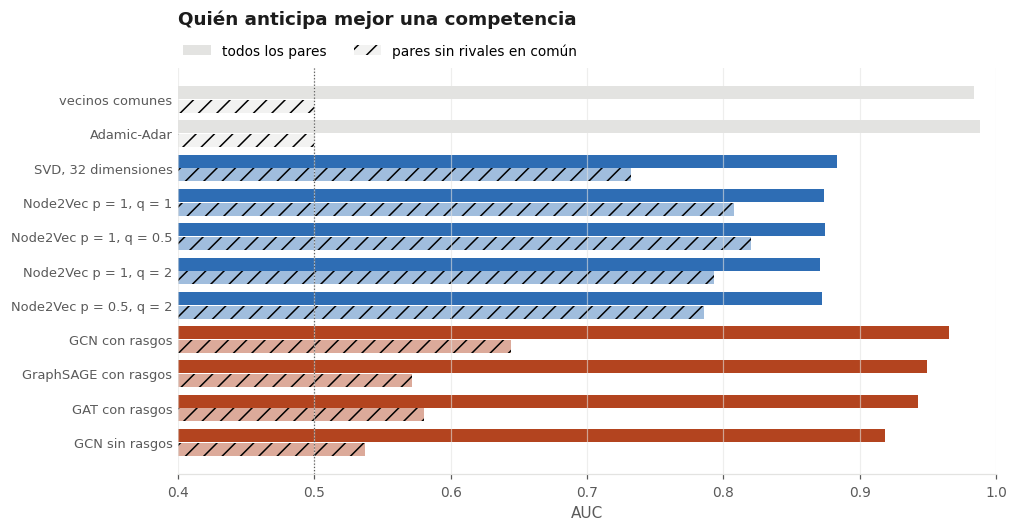

In [6]:
r = rasgos.set_index("nodo").reindex(idx)
LOGS = ["n_ganados", "monto_total", "monto_mediano", "n_entidades", "n_departamentos", "n_familias"]
TASAS = ["cuota_cliente_top", "meses_activos", "tasa_victoria", "pct_postor_unico", "pct_sin_concurso", "pct_obras"]
def estandarizar(M):
    return (M - M.mean(0)) / np.where(M.std(0) > 0, M.std(0), 1)
X_gnn = estandarizar(np.c_[np.log1p(r[LOGS].fillna(0).values), r[TASAS].fillna(0).values, np.log1p(grado_b)])
X_grado = np.c_[np.ones(n), estandarizar(np.log1p(grado_b)[:, None])]
EPOCAS = 200
gnn_b, tiempos_gnn = {}, {}
for nombre, tipo, X_ in [("GCN con rasgos", "GCN", X_gnn), ("GraphSAGE con rasgos", "GraphSAGE", X_gnn),
                         ("GAT con rasgos", "GAT", X_gnn), ("GCN sin rasgos", "GCN", X_grado)]:
    with cronometro(nombre):
        res = guardado(f"gnn_{tipo}_{'rasgos' if X_ is X_gnn else 'grado'}", lambda: entrenar_gnn(tipo, B, X_, epocas=EPOCAS))
    gnn_b[nombre], tiempos_gnn[nombre] = res[0], res[2]
    sc = np.einsum("ij,ij->i", res[0][pares[:, 0]], res[0][pares[:, 1]])
    filas.append({"metodo": nombre, "tipo": "GNN", "AUC": auc_en(sc, todos),
                  "AUC_sin_rivales_comunes": auc_en(sc, sin_comun), "AUC_bajo_grado": auc_en(sc, bajo)})
auc = pd.DataFrame(filas)
auc["segundos"] = auc.metodo.map(tiempos_gnn)
print(auc.round(3).to_string(index=False))
exportar(auc.round(4), "p6_prediccion_enlaces", "AUC de prediccion de enlaces de cada metodo, total, sin rivales en comun y en grado bajo")

fig, ax = plt.subplots(figsize=(9.6, 4.8))
yy = np.arange(len(auc))[::-1]
ax.barh(yy + .2, auc.AUC, .38, color=[REJILLA if t == "heurística" else (ROJO if t == "GNN" else AZUL) for t in auc.tipo], label="todos los pares")
ax.barh(yy - .2, auc.AUC_sin_rivales_comunes, .38, color=[REJILLA if t == "heurística" else (ROJO if t == "GNN" else AZUL) for t in auc.tipo],
        alpha=.45, hatch="//", label="pares sin rivales en común")
ax.set_yticks(yy, auc.metodo, fontsize=8.5); ax.set_xlim(0.4, 1.0); ax.axvline(.5, color=SUAVE, lw=.8, ls=":")
ax.set_xlabel("AUC"); ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncols=2, borderaxespad=0)
ax.set_title("Quién anticipa mejor una competencia", loc="left", pad=28); ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=.6); ax.spines["left"].set_visible(False)
a_ = auc.set_index("metodo")
mejor_total = a_.AUC.idxmax()
cand = a_[a_.tipo != "heurística"]
mejor_sin = cand.AUC_sin_rivales_comunes.idxmax()
mejor_clasico_sin = a_[a_.tipo == "embedding"].AUC_sin_rivales_comunes.idxmax()
mejor_gnn = a_[a_.tipo == "GNN"].AUC.idxmax()
n_sin = int(sin_comun[:len(pos)].sum())
mejor_gnn_sin = a_[a_.tipo == "GNN"].AUC_sin_rivales_comunes.idxmax()
figura(fig, "f34_prediccion_enlaces", f"""
Sobre todos los pares gana una heurística simple, {mejor_total}, con AUC de {a_.loc[mejor_total,'AUC']:.3f}: la competencia
es muy transitiva, y si dos proveedores comparten rivales casi seguro se encuentran. Entre los embeddings gana la red
neuronal, {mejor_gnn}, con {a_.loc[mejor_gnn,'AUC']:.2f} frente a {a_[a_.tipo == 'embedding'].AUC.max():.2f} de los clásicos, y la
ventaja viene de los rasgos: sin ellos la GCN baja a {a_.loc['GCN sin rasgos','AUC']:.2f}. El cuadro cambia en las barras
rayadas, los pares que todavía no comparten ningún rival, donde las heurísticas no pueden ordenar nada: ahí gana
{mejor_sin} con {a_.loc[mejor_sin,'AUC_sin_rivales_comunes']:.2f}, y la mejor red neuronal cae a
{a_.loc[mejor_gnn_sin,'AUC_sin_rivales_comunes']:.2f}. La red neuronal aprendió quién es un proveedor activo; Node2Vec,
a qué mercado pertenece, que es lo que sirve para anticipar una competencia nueva. Son solo {n_sin} aristas en ese
conjunto, así que la diferencia se lee como tendencia y no como cifra exacta.""")

## 6. Tarea 2: qué estructura capturan, vista en dos dimensiones

Se proyectan los embeddings con t-SNE, que conserva vecindarios: puntos cercanos en el plano son proveedores cercanos en el embedding, pero las distancias largas no se interpretan. Se colorea la misma nube dos veces, por departamento y por perfil de la Parte II, sobre una muestra de 3.000 proveedores.

t-SNE de cada embedding: 112.54 s



Lectura de f35_tsne_embeddings
Con el embedding de Node2Vec que explora hacia afuera (q igual a 0,5), la nube se parte en islas, y cada isla es un mercado de rubro: a la izquierda, los seis rubros más frecuentes ocupan zonas propias y el gris es el resto. A la derecha, la misma nube coloreada por perfil de la Parte II queda mayormente mezclada: el proveedor competitivo típico está en todas las islas. Las excepciones confirman la regla: los contratistas de obra y los grandes recurrentes forman zonas propias porque su rubro es su mercado. El embedding aprendió dónde compite cada proveedor, no cómo se comporta, y la sección siguiente lo mide.



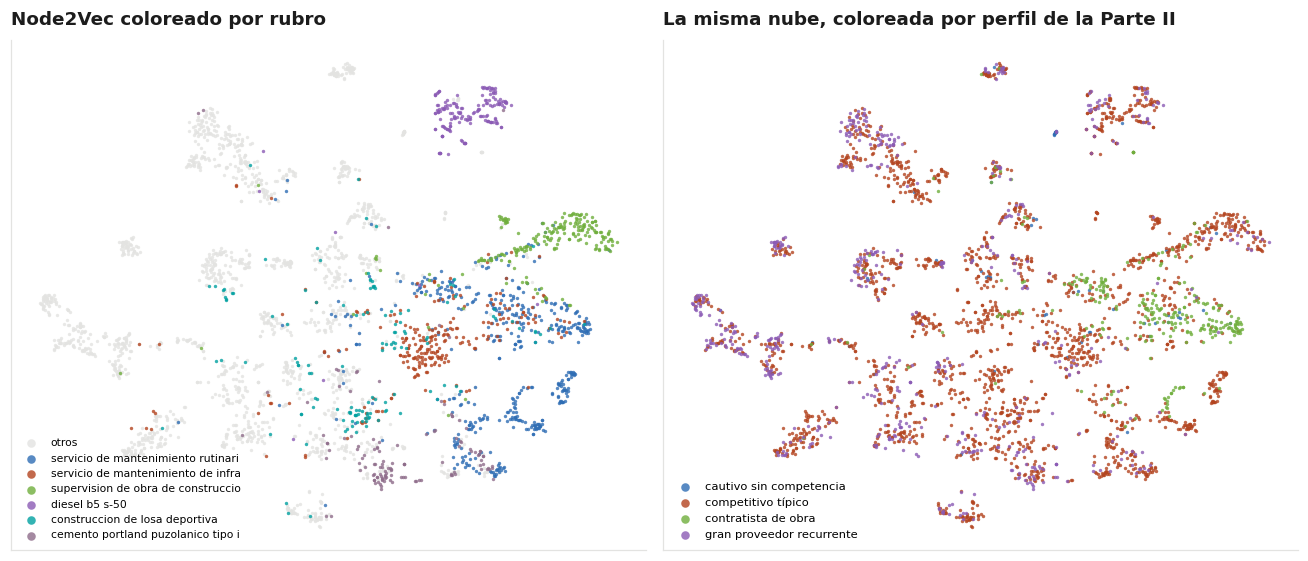

In [7]:
rng = np.random.default_rng(0)
muestra = np.sort(rng.choice(n, 3000, replace=False))
deps = info.departamento.value_counts().index[:6]
info["region"] = np.where(info.departamento.isin(deps), info.departamento, "otros")
rubros = info.item_tipico.value_counts().index[:6]
info["rubro"] = np.where(info.item_tipico.isin(rubros), info.item_tipico.str[:40], "otros")
def proyectar():
    salida = {}
    for clave, Z in ([("svd", Z_svd)] + [(f"n2v_{p:g}_{q:g}", emb[(p, q)]["Z"]) for p, q in CONFIGS]
                     + [("gnn_GraphSAGE con rasgos", gnn_b["GraphSAGE con rasgos"])]):
        salida[clave] = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(Z[muestra])
    return salida
with cronometro("t-SNE de cada embedding"):
    tsne = guardado("tsne_v2", proyectar)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5.2))
P = tsne["n2v_1_0.5"]
ru = [x for x in info.rubro.value_counts().index if x != "otros"][:6]
colores = dict(zip(ru + ["otros"], PALETA + ["#8E6C8A", REJILLA]))
for r_ in ["otros"] + ru:
    m = info.rubro.values[muestra] == r_
    a1.scatter(P[m, 0], P[m, 1], s=5, color=colores[r_], label=r_.lower()[:34], alpha=.8, linewidths=0)
a1.set_title("Node2Vec coloreado por rubro", loc="left", pad=10); a1.legend(fontsize=7, markerscale=2.5, loc="best")
perf = info.perfil.values[muestra]
for k, (pf, c) in enumerate(zip(sorted(info.perfil.dropna().unique()), [AZUL, ROJO, VERDE, MORADO])):
    m = perf == pf
    a2.scatter(P[m, 0], P[m, 1], s=5, color=c, label=pf, alpha=.8, linewidths=0)
a2.set_title("La misma nube, coloreada por perfil de la Parte II", loc="left", pad=10); a2.legend(fontsize=7.5, markerscale=2.5)
for a in (a1, a2): a.set_xticks([]); a.set_yticks([])
fig.tight_layout()
figura(fig, "f35_tsne_embeddings", """
Con el embedding de Node2Vec que explora hacia afuera (q igual a 0,5), la nube se parte en islas, y cada isla es un
mercado de rubro: a la izquierda, los seis rubros más frecuentes ocupan zonas propias y el gris es el resto. A la
derecha, la misma nube coloreada por perfil de la Parte II queda mayormente mezclada: el proveedor competitivo típico
está en todas las islas. Las excepciones confirman la regla: los contratistas de obra y los grandes recurrentes forman
zonas propias porque su rubro es su mercado. El embedding aprendió dónde compite cada proveedor, no cómo se comporta,
y la sección siguiente lo mide.""")

## 7. Tarea 3: ¿convergen clústeres, comunidades y embeddings?

Se agrupan los embeddings con KMeans y se mide el acuerdo, con ARI y NMI, contra cuatro etiquetas: el perfil de la Parte II, la comunidad nacional de la Parte V, el departamento y la familia CUBSO. Para que el número de grupos no decida el resultado, se usan dos valores: k = 4, el de la Parte II, y k = 30.

El contraste es el **grafo KNN de rasgos**: sus aristas unen proveedores parecidos en los 12 rasgos de comportamiento, así que sus embeddings deberían reencontrar los perfiles de la Parte II y no la región. Si eso pasa, el resultado anterior no es un defecto del método sino una propiedad del grafo: el embedding captura lo que el grafo codifica.

grafo KNN de rasgos y su embedding: 1.63 s


etiqueta                         perfil de la Parte II  comunidad de la Parte V  departamento  familia CUBSO
embedding                                                                                                   
SVD, competencia                                 0.097                    0.604         0.129          0.496
Node2Vec q = 0,5, competencia                    0.091                    0.622         0.178          0.592
Node2Vec q = 2, competencia                      0.094                    0.622         0.161          0.600
GraphSAGE, competencia y rasgos                  0.137                    0.480         0.132          0.436
SVD, KNN de rasgos                               0.281                    0.213         0.069          0.171
etiqueta                         comunidad de la Parte V  departamento  familia CUBSO  perfil de la Parte II
embedding                                                                                                   
GraphSAGE, competen


Lectura de f36_convergencia
Los embeddings del grafo de competencia coinciden con la comunidad de la Parte V (NMI de 0.62) y con la familia CUBSO (0.59), poco con el departamento (0.18) y casi nada con el perfil de la Parte II (0.09). El embedding del grafo KNN de rasgos hace lo contrario: reencuentra el perfil (0.28) y no el rubro (0.17). GraphSAGE, que ve las dos cosas, queda en medio: perfil 0.14 y comunidad 0.48. La respuesta a si convergen es que sí, dentro de cada lente: comunidades y embeddings de la red coinciden entre sí, y clústeres y embeddings de rasgos coinciden entre sí. Entre lentes no, porque miden cosas distintas: en qué mercado compite un proveedor y cómo se comporta.



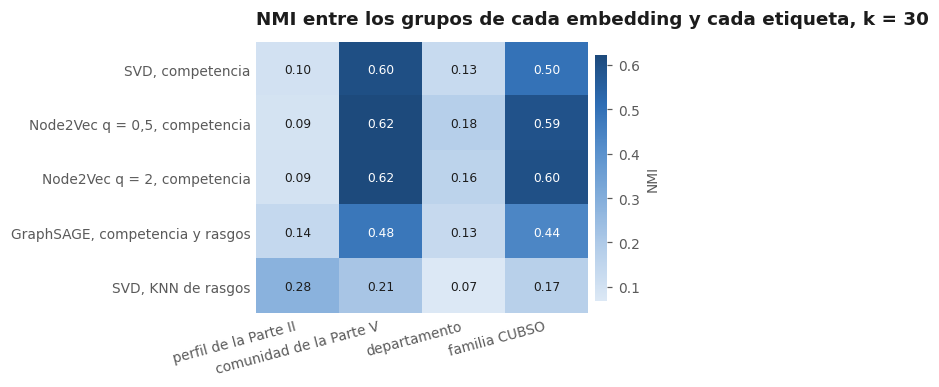

In [8]:
LOGS = ["n_ganados", "monto_total", "monto_mediano", "n_entidades", "n_departamentos", "n_familias"]
TASAS = ["cuota_cliente_top", "meses_activos", "tasa_victoria", "pct_postor_unico", "pct_sin_concurso", "pct_obras"]
r = rasgos.set_index("nodo").reindex(idx)
X = np.c_[np.log1p(r[LOGS].fillna(0).values), r[TASAS].fillna(0).values]
X = (X - X.mean(0)) / X.std(0)
with cronometro("grafo KNN de rasgos y su embedding"):
    A_knn = grafo_knn(X, 10)
    Z_knn, _ = embedding_svd(A_knn, D)

etiquetas = {"perfil de la Parte II": info.perfil.values, "comunidad de la Parte V": info.comunidad.values,
             "departamento": info.departamento.values, "familia CUBSO": info.familia.values}
embeddings = {"SVD, competencia": Z_svd, "Node2Vec q = 0,5, competencia": emb[(1.0, 0.5)]["Z"],
              "Node2Vec q = 2, competencia": emb[(1.0, 2.0)]["Z"],
              "GraphSAGE, competencia y rasgos": gnn_b["GraphSAGE con rasgos"], "SVD, KNN de rasgos": Z_knn}
filas = []
for nombre, Z in embeddings.items():
    Zn = Z / np.maximum(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12)
    for k in [4, 30]:
        g = KMeans(k, n_init=5, random_state=0).fit_predict(Zn)
        for et, v in etiquetas.items():
            ok = pd.notna(v)
            filas.append({"embedding": nombre, "k": k, "etiqueta": et, "ARI": ari(g[ok], v[ok]), "NMI": nmi(g[ok], v[ok])})
conv = pd.DataFrame(filas)
exportar(conv.round(4), "p6_convergencia", "ARI y NMI entre grupos de embeddings y las etiquetas de las partes anteriores")
tabla = conv[conv.k == 30].pivot(index="embedding", columns="etiqueta", values="NMI").reindex(list(embeddings))
tabla = tabla[list(etiquetas)]
print(tabla.round(3))
print(conv[conv.k == 4].pivot(index="embedding", columns="etiqueta", values="ARI").round(3))
fig, ax = mapa_calor(tabla, "NMI entre los grupos de cada embedding y cada etiqueta, k = 30", "NMI", "{:.2f}")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
t = tabla
figura(fig, "f36_convergencia", f"""
Los embeddings del grafo de competencia coinciden con la comunidad de la Parte V (NMI de
{t.loc['Node2Vec q = 0,5, competencia','comunidad de la Parte V']:.2f}) y con la familia CUBSO
({t.loc['Node2Vec q = 0,5, competencia','familia CUBSO']:.2f}), poco con el departamento
({t.loc['Node2Vec q = 0,5, competencia','departamento']:.2f}) y casi nada con el perfil de la Parte II
({t.loc['Node2Vec q = 0,5, competencia','perfil de la Parte II']:.2f}). El embedding del grafo KNN de rasgos hace lo
contrario: reencuentra el perfil ({t.loc['SVD, KNN de rasgos','perfil de la Parte II']:.2f}) y no el rubro
({t.loc['SVD, KNN de rasgos','familia CUBSO']:.2f}). GraphSAGE, que ve las dos cosas, queda en medio: perfil
{t.loc['GraphSAGE, competencia y rasgos','perfil de la Parte II']:.2f} y comunidad
{t.loc['GraphSAGE, competencia y rasgos','comunidad de la Parte V']:.2f}. La respuesta a si convergen es que sí, dentro de
cada lente: comunidades y embeddings de la red coinciden entre sí, y clústeres y embeddings de rasgos coinciden entre
sí. Entre lentes no, porque miden cosas distintas: en qué mercado compite un proveedor y cómo se comporta.""")

## 8. Para qué sirven juntas las dos lentes

Si posición competitiva y comportamiento son independientes, cruzarlas da información que ninguna da sola. Un caso concreto: los vecinos más cercanos de un proveedor cautivo en el embedding de competencia son proveedores de su mismo mercado que sí compiten. Son candidatos naturales a invitar cuando la entidad que depende del cautivo amplíe su estudio de mercado. Es la misma idea de los sustitutos de la Parte III, ahora desde la red de competencia y no desde la matriz de compras.

In [9]:
Zq = emb[(1.0, 0.5)]["Z"]; Zq = Zq / np.linalg.norm(Zq, axis=1, keepdims=True)
cautivos = np.where(info.perfil.str.startswith("cautivo").fillna(False).values)[0]
competitivos = info.perfil.isin(["competitivo típico", "gran proveedor recurrente"]).values
ejemplos = []
for i in cautivos[np.argsort(-info.monto_total.values[cautivos])][:8]:
    sim = Zq @ Zq[i]; sim[i] = -1; sim[~competitivos] = -1
    vec = np.argsort(-sim)[:3]
    ejemplos.append({"cautivo": info.nombre.iloc[i], "departamento": info.departamento.iloc[i],
                     "rubro": str(info.item_tipico.iloc[i])[:40], "sustitutos_que_compiten": " | ".join(info.nombre.iloc[vec].str[:38]),
                     "mismo_departamento_pct": round(100 * np.mean(info.departamento.values[vec] == info.departamento.iloc[i]))})
ejemplos = pd.DataFrame(ejemplos)
print(ejemplos.to_string(index=False))
exportar(ejemplos, "p6_sustitutos_red", "Cautivos y los proveedores competitivos mas cercanos en el embedding de competencia")

                                                       cautivo departamento                                    rubro                                                                                                  sustitutos_que_compiten  mismo_departamento_pct
                            PROYECTA INGENIEROS CIVILES S.A.C.         LIMA SUPERVISION DE OBRA DE CONSTRUCCION DE C                                 CONSORCIO SUPERVISOR NORTE | CONSORCIO SUPERVISOR LOS ANDES | CONSORCIO CONSULTOR THIAGO                       0
MAX VISION PERU SOCIEDAD COMERCIAL DE RESPONSABILIDAD LIMITADA         LIMA SODIO CLORURO 0,9 % (900 mg/100 mL) INY                                     PFIZER S A | FARMA VITA GROUP SOCIEDAD ANONIMA CERR | DISTRIBUIDORA CONTINENTAL 6 S A                     100
                  COMPACT MAQUINARIAS SOCIEDAD ANONIMA CERRADA        PIURA SERVICIO DE MANTENIMIENTO RUTINARIO DE C                                 INVERSIONES DEMIFORT S.A.C. | TAVI E MPRESA INDIVIDUAL DE RESPONS

,cautivo,departamento,rubro,sustitutos_que_compiten,mismo_departamento_pct
0,PROYECTA INGENIEROS CIVILES S.A.C.,LIMA,SUPERVISION DE OBRA DE CONSTRUCCION DE C,CONSORCIO SUPERVISOR NORTE | CONSORCIO SUPERVISOR LOS ANDES ...,0
1,MAX VISION PERU SOCIEDAD COMERCIAL DE RESPONSABILIDAD LIMITADA,LIMA,"SODIO CLORURO 0,9 % (900 mg/100 mL) INY",PFIZER S A | FARMA VITA GROUP SOCIEDAD ANONIMA CERR | DISTRI...,100
2,COMPACT MAQUINARIAS SOCIEDAD ANONIMA CERRADA,PIURA,SERVICIO DE MANTENIMIENTO RUTINARIO DE C,INVERSIONES DEMIFORT S.A.C. | TAVI E MPRESA INDIVIDUAL DE RE...,0
3,TICONA MENDEZ NESTOR FAUSTO,LIMA,HENO DE ALFALFA PARA ALIMENTO DE ANIMALE,EUSEBIO PADILLA ARTURO CESAR | INVERSIONES NORMITAS E.I.R.L....,33
4,CAMAFRA MOTORS S.A.C.,PIURA,SERVICIO DE MANTENIMIENTO RUTINARIO DE C,REPRESENTACIONES & CONSTRUCCIONES CORD | DABRE CORPORATION S...,33
5,CES CONSULTING ENGINEERS SALZGITTER GMBH SUCURSAL DEL PERU,LIMA,SUPERVISION DE OBRA DE CONSTRUCCION DE C,CHAPOÑAN CAJUSOL LEONCIO | REATEGUI TORRES LILI | AVOG CONTR...,33
6,SERVICIOS GENERALES VIVIANA EIRL,PIURA,SERVICIO DE MANTENIMIENTO RUTINARIO DE C,COMERCIALIZADORA Y MULTISERVICIOS CHUN | REPRESENTACIONES & ...,33
7,IBE CONTRATISTAS GENERALES S.A.C.,ANCASH,SERVICIO DE MANTENIMIENTO RUTINARIO DE C,LIXANT S.R.L. CONSULTORES Y CONTRATIST | CONSORCIO NUEVO HOR...,33


## 9. Hallazgos de la Parte VI

In [10]:
hallazgo("VI", "La competencia es transitiva, y la red neuronal no supera a contar rivales",
         f"""Contar rivales en común anticipa quién va a competir con quién con AUC de {a_.loc[mejor_total,'AUC']:.2f}, mejor que
         cualquier embedding: si dos proveedores comparten rivales, casi seguro se encuentran. La red neuronal con los
         rasgos de la Parte II es el mejor embedding ({a_.loc[mejor_gnn,'AUC']:.2f} frente a {a_[a_.tipo == 'embedding'].AUC.max():.2f} de
         SVD y Node2Vec), pero para la competencia sin antecedentes, pares sin ningún rival en común, gana {mejor_sin}
         ({a_.loc[mejor_sin,'AUC_sin_rivales_comunes']:.2f} frente a {a_.loc[mejor_gnn_sin,'AUC_sin_rivales_comunes']:.2f}).""",
         """Para ampliar la lista de invitados a cotizar, usar rivales en común como primer criterio y la cercanía en el
         embedding de Node2Vec para proponer proveedores sin antecedentes en ese mercado. La red neuronal no se justifica
         para este uso: cuesta más y no mejora a la heurística.""",
         "f34_prediccion_enlaces, p6_prediccion_enlaces")
hallazgo("VI", "Dónde compite un proveedor y cómo se comporta son dos dimensiones distintas",
         f"""Los grupos de los embeddings de competencia coinciden con las comunidades de la Parte V
         (NMI {t.loc['Node2Vec q = 0,5, competencia','comunidad de la Parte V']:.2f}) y con el rubro, y casi nada con
         los perfiles de la Parte II (NMI {t.loc['Node2Vec q = 0,5, competencia','perfil de la Parte II']:.2f}). El embedding
         de un grafo KNN de rasgos hace lo opuesto. Clústeres, comunidades y embeddings convergen dentro de cada
         lente, no entre lentes.""",
         """Combinar las dos lentes en la supervisión: el perfil de la Parte II para saber qué tipo de proveedor
         es, y la comunidad o el embedding para saber en qué mercado comparar su desempeño. Un cautivo se evalúa
         contra los proveedores competitivos de su mismo mercado, que el embedding identifica.""",
         "f35_tsne_embeddings, f36_convergencia, p6_convergencia, p6_sustitutos_red")


HALLAZGO. La competencia es transitiva, y la red neuronal no supera a contar rivales
Contar rivales en común anticipa quién va a competir con quién con AUC de 0.99, mejor que cualquier embedding: si dos proveedores comparten rivales, casi seguro se encuentran. La red neuronal con los rasgos de la Parte II es el mejor embedding (0.97 frente a 0.88 de SVD y Node2Vec), pero para la competencia sin antecedentes, pares sin ningún rival en común, gana Node2Vec p = 1, q = 0.5 (0.82 frente a 0.64).
Accion propuesta: Para ampliar la lista de invitados a cotizar, usar rivales en común como primer criterio y la cercanía en el embedding de Node2Vec para proponer proveedores sin antecedentes en ese mercado. La red neuronal no se justifica para este uso: cuesta más y no mejora a la heurística.


HALLAZGO. Dónde compite un proveedor y cómo se comporta son dos dimensiones distintas
Los grupos de los embeddings de competencia coinciden con las comunidades de la Parte V (NMI 0.62) y con el rubro, y cas

In [11]:
# Para el reporte: coordenadas de t-SNE de cada embedding con sus etiquetas, para elegir p y q en vivo.
puntos = info.iloc[muestra][["nombre", "region", "rubro", "perfil", "comunidad"]].reset_index(drop=True)
puntos["perfil"] = puntos.perfil.fillna("sin perfil")
for clave, P in tsne.items():
    puntos[f"{clave}_x"] = P[:, 0].round(2); puntos[f"{clave}_y"] = P[:, 1].round(2)
exportar(puntos, "p6_tsne", "Coordenadas t-SNE de 3.000 proveedores para cada embedding")
exportar(pd.DataFrame([{"proveedores": n, "aristas": A.nnz // 2, "sin_competir": sin_competir,
                        "auc_mejor": round(a_.loc[mejor_total, 'AUC'], 3), "metodo_mejor": mejor_total,
                        "auc_sin_comun_mejor": round(a_.loc[mejor_sin, 'AUC_sin_rivales_comunes'], 3), "metodo_sin_comun": mejor_sin,
                        "auc_sin_comun_clasico": round(a_.loc[mejor_clasico_sin, 'AUC_sin_rivales_comunes'], 3),
                        "auc_gnn": round(a_.loc[mejor_gnn, 'AUC'], 3), "metodo_gnn": mejor_gnn,
                        "auc_gnn_sin_comun": round(a_.loc[mejor_gnn_sin, 'AUC_sin_rivales_comunes'], 3),
                        "auc_gcn_sin_rasgos": round(a_.loc['GCN sin rasgos', 'AUC'], 3), "positivos_sin_comun": n_sin,
                        "nmi_comunidad": round(t.loc['Node2Vec q = 0,5, competencia', 'comunidad de la Parte V'], 3),
                        "nmi_departamento": round(t.loc['Node2Vec q = 0,5, competencia', 'departamento'], 3),
                        "nmi_perfil": round(t.loc['Node2Vec q = 0,5, competencia', 'perfil de la Parte II'], 3),
                        "nmi_knn_perfil": round(t.loc['SVD, KNN de rasgos', 'perfil de la Parte II'], 3)}]),
         "p6_resumen", "Cifras clave de la Parte VI")
exportar(pd.DataFrame(FIGURAS), "p6_figuras", "Figuras de la Parte VI con su lectura")
exportar(pd.DataFrame(HALLAZGOS), "p6_hallazgos", "Hallazgos de la Parte VI con su accion propuesta")

,parte,titulo,insight,accion,evidencia
0,VI,"La competencia es transitiva, y la red neuronal no supera a ...",Contar rivales en común anticipa quién va a competir con qui...,"Para ampliar la lista de invitados a cotizar, usar rivales e...","f34_prediccion_enlaces, p6_prediccion_enlaces"
1,VI,Dónde compite un proveedor y cómo se comporta son dos dimens...,Los grupos de los embeddings de competencia coinciden con la...,Combinar las dos lentes en la supervisión: el perfil de la P...,"f35_tsne_embeddings, f36_convergencia, p6_convergencia, p6_s..."


**Cierre.** Para anticipar qué proveedores van a encontrarse en un proceso, contar rivales en común es difícil de superar. La validación con redes neuronales da una respuesta clara: GCN, GraphSAGE y GAT superan a los embeddings clásicos sobre todos los pares gracias a los rasgos de cada proveedor, pero no a la heurística, y para la competencia sin antecedentes el mejor es Node2Vec. Además, los embeddings responden la pregunta de convergencia con un matiz que vale más que un sí o un no: los métodos convergen dentro de cada lente. Lo que el grafo de coparticipación codifica, y lo que sus comunidades y embeddings reencuentran, es el territorio y el rubro donde se compite. Lo que codifican los rasgos de la Parte II es el comportamiento. Las dos lentes juntas permiten comparar a cada proveedor con sus pares de mercado.

**Decisiones que conviene recordar.** Se embebió el grafo de coparticipación y no el KNN, porque el KNN de rasgos solo devuelve lo que ya dijeron los clústeres; el contraste está medido. La evaluación de enlaces reserva aristas sin aislar nodos, compara contra heurísticas clásicas y separa los pares sin rivales en común, porque ahí está la pregunta de negocio. Las redes neuronales se probaron como validación, con la misma partición, y una ablación sin rasgos muestra de dónde viene su ventaja. GAT, la más compleja, no supera a GCN y tarda más de diez veces lo que ella. El t-SNE solo se usa para mirar, y las conclusiones salen de ARI y NMI.

**Encuadre ético.** Un embedding cercano no implica relación entre proveedores; implica que ocupan lugares parecidos en la red. Las listas de sustitutos amplían la competencia y no señalan a nadie.